### **UNSW-NB15: Machine Learning vs Deep Learning**


In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping


### **1. Configuration**

In [2]:
RANDOM_STATE = 42
TARGET = "label"

tf.keras.utils.set_random_seed(RANDOM_STATE)

# Project paths
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "capstone":
    CAPSTONE_DIR = CURRENT_DIR
    PROJECT_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "capstone").exists():
    PROJECT_DIR = CURRENT_DIR
    CAPSTONE_DIR = PROJECT_DIR / "capstone"
elif (CURRENT_DIR.parent / "capstone").exists():
    PROJECT_DIR = CURRENT_DIR.parent
    CAPSTONE_DIR = PROJECT_DIR / "capstone"
else:
    raise FileNotFoundError("Could not locate the capstone directory.")

DATASET_DIR = PROJECT_DIR / "dataset"
RESULTS_DIR = CAPSTONE_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


### **2. Load Dataset**

In [3]:
print("\nLoading datasets...")

df_train = pd.read_parquet(DATASET_DIR / "train_full.parquet")
df_test = pd.read_parquet(DATASET_DIR / "test_full.parquet")

print("Training shape:", df_train.shape)
print("Testing shape :", df_test.shape)


Loading datasets...
Training shape: (175341, 45)
Testing shape : (82332, 45)


### **3. Separate Features and Target**

In [4]:
DROP_COLUMNS = ["id", "attack_cat", "traffic_type"]

columns_to_drop = [
    col for col in DROP_COLUMNS
    if col in df_train.columns
]

X_train = df_train.drop(columns=columns_to_drop + [TARGET])
y_train = df_train[TARGET]

test_columns_to_drop = [
    col for col in DROP_COLUMNS
    if col in df_test.columns
]

X_test = df_test.drop(
    columns=test_columns_to_drop + [TARGET]
)

y_test = df_test[TARGET]

# Ensure the test features follow the training feature order
X_test = X_test[X_train.columns]

print("\nNumber of features:", X_train.shape[1])


Number of features: 42


### **4. Load Tuned XGBoost Model**

In [6]:
print("\nLoading tuned XGBoost model...")

xgb_model = joblib.load(
    RESULTS_DIR / "best_xgb_pipeline.joblib"
)

print("Tuned XGBoost model loaded successfully.")


Loading tuned XGBoost model...
Tuned XGBoost model loaded successfully.


### **5. Evaluate XGBoost**

In [7]:
print("\nEvaluating XGBoost...")

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]


Evaluating XGBoost...


### **6. Prepare Data for Neural Network**

In [8]:
# Split training data into training and validation sets.
# The original test dataset remains untouched.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))



Numerical features: 39
Categorical features: 3


C:\Users\Prateek\AppData\Local\Temp\ipykernel_54504\1952574845.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


### **7. Neural Network Preprocessing**

In [9]:
nn_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "encoder",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                        dtype=np.float32
                    )
                )
            ]),
            categorical_features
        )
    ],
    sparse_threshold=0
)

# Fit preprocessing only on the training portion
X_fit_processed = nn_preprocessor.fit_transform(X_fit)

X_val_processed = nn_preprocessor.transform(X_val)

# Convert to float32 for TensorFlow
X_fit_processed = np.asarray(
    X_fit_processed,
    dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed,
    dtype=np.float32
)

y_fit = y_fit.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)

print("\nProcessed training shape:", X_fit_processed.shape)
print("Processed validation shape:", X_val_processed.shape)


Processed training shape: (140272, 192)
Processed validation shape: (35069, 192)


### **8. Define Neural Network Architecture**

In [10]:
def build_neural_network(input_dim):

    model = Sequential([
        Input(shape=(input_dim,)),

        Dense(128, activation="relu"),
        Dropout(0.3),

        Dense(64, activation="relu"),
        Dropout(0.2),

        Dense(32, activation="relu"),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


### **9. Train Neural Network with Early Stopping**

In [11]:
print("\nTraining Neural Network...")

nn_model = build_neural_network(
    X_fit_processed.shape[1]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = nn_model.fit(
    X_fit_processed,
    y_fit,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=1024,
    callbacks=[early_stopping],
    verbose=1
)

# Identify the best epoch using validation loss
best_epoch = int(
    np.argmin(history.history["val_loss"]) + 1
)

print("\nBest epoch:", best_epoch)


Training Neural Network...
Epoch 1/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9024 - loss: 0.2492 - val_accuracy: 0.9382 - val_loss: 0.1384
Epoch 2/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9345 - loss: 0.1439 - val_accuracy: 0.9405 - val_loss: 0.1254
Epoch 3/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9370 - loss: 0.1324 - val_accuracy: 0.9415 - val_loss: 0.1212
Epoch 4/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9376 - loss: 0.1284 - val_accuracy: 0.9431 - val_loss: 0.1185
Epoch 5/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9389 - loss: 0.1252 - val_accuracy: 0.9437 - val_loss: 0.1171
Epoch 6/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9395 - loss: 0.1232 - val_accuracy: 0.9439 - val_loss: 0.1161
Epoch 7/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9403 - loss: 0.1220 - val_accuracy: 0.9441 - val_loss: 0.1151
Epoch 8/50
137/137 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9400 - los

### **10. Retrain Neural Network on Complete Training Dataset**

In [12]:
print("\nRetraining neural network on complete training dataset...")

# Fit a fresh preprocessor on all training data
final_nn_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "encoder",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                        dtype=np.float32
                    )
                )
            ]),
            categorical_features
        )
    ],
    sparse_threshold=0
)

X_train_nn = final_nn_preprocessor.fit_transform(X_train)
X_test_nn = final_nn_preprocessor.transform(X_test)

X_train_nn = np.asarray(X_train_nn, dtype=np.float32)
X_test_nn = np.asarray(X_test_nn, dtype=np.float32)

y_train_nn = y_train.to_numpy(dtype=np.float32)

# Build a fresh model
final_nn_model = build_neural_network(
    X_train_nn.shape[1]
)

# Train using the best epoch count
final_nn_model.fit(
    X_train_nn,
    y_train_nn,
    epochs=best_epoch,
    batch_size=1024,
    verbose=1
)



Retraining neural network on complete training dataset...
Epoch 1/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9074 - loss: 0.2305
Epoch 2/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9358 - loss: 0.1384
Epoch 3/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9387 - loss: 0.1286
Epoch 4/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9394 - loss: 0.1245
Epoch 5/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9403 - loss: 0.1221
Epoch 6/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9409 - loss: 0.1204
Epoch 7/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9416 - loss: 0.1191
Epoch 8/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9422 - loss: 0.1180
Epoch 9/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9424 - loss: 0.1170
Epoch 10/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9429 - loss: 0.1163
Epoch 11/34
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9428 - loss: 

### **11. Evaluate Neural Network**

In [13]:
print("\nEvaluating Neural Network...")

nn_prob = final_nn_model.predict(
    X_test_nn,
    verbose=0
).ravel()

# Convert probabilities into class predictions
nn_pred = (nn_prob >= 0.5).astype(int)



Evaluating Neural Network...


### **12. Calculate Performance Metrics**

In [14]:
def evaluate_model(model_name, y_true, y_pred, y_prob):

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob)
    }


xgb_results = evaluate_model(
    "Tuned XGBoost",
    y_test,
    xgb_pred,
    xgb_prob
)

nn_results = evaluate_model(
    "Neural Network (MLP)",
    y_test,
    nn_pred,
    nn_prob
)


### **13. Model Comparison**

In [15]:
comparison_df = pd.DataFrame([
    xgb_results,
    nn_results
])

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("MACHINE LEARNING VS DEEP LEARNING")
print("=" * 65)

print(comparison_df.round(4).to_string(index=False))

comparison_df.to_csv(
    RESULTS_DIR / "ml_vs_dl_comparison.csv",
    index=False
)




MACHINE LEARNING VS DEEP LEARNING
               Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
       Tuned XGBoost    0.8731     0.8213  0.9836    0.8951   0.9842  0.9884
Neural Network (MLP)    0.8691     0.8205  0.9758    0.8914   0.9778  0.9837


### **14. Classification Reports**

In [16]:
print("\nTuned XGBoost Classification Report:")
print(classification_report(y_test, xgb_pred))

print("\nNeural Network Classification Report:")
print(classification_report(y_test, nn_pred))



Tuned XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.74      0.84     37000
           1       0.82      0.98      0.90     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.87     82332
weighted avg       0.89      0.87      0.87     82332


Neural Network Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.74      0.84     37000
           1       0.82      0.98      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.89      0.86      0.86     82332
weighted avg       0.88      0.87      0.87     82332



### **15. Performance Comparison Chart**

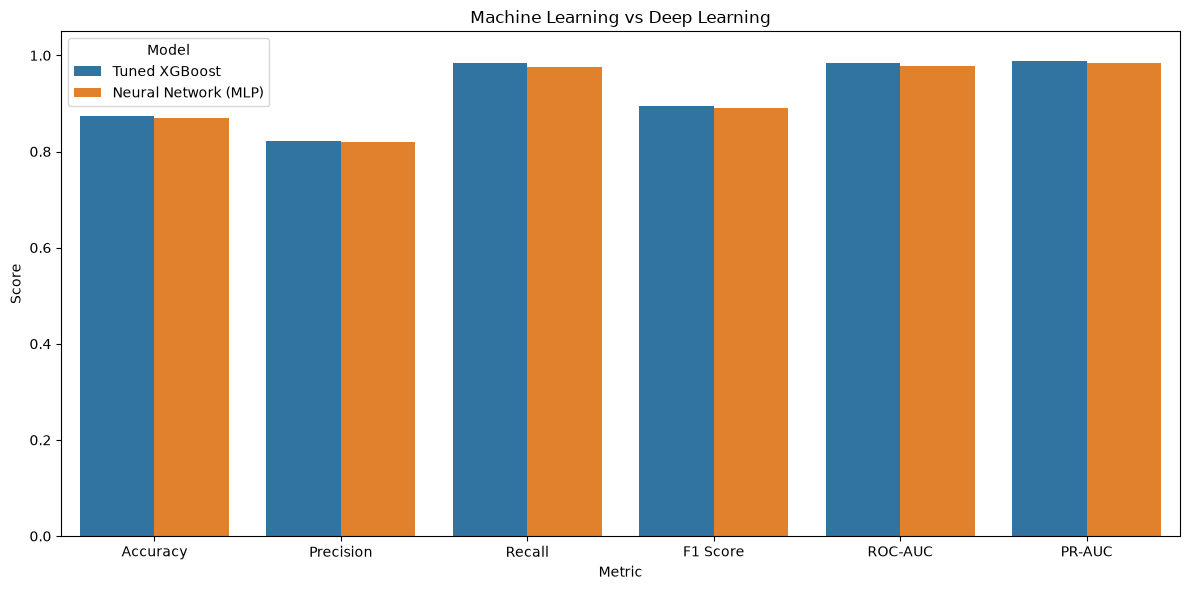

In [17]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

plot_df = comparison_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning vs Deep Learning")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ml_vs_dl_comparison.png",
    dpi=300
)

plt.show()

### **16. Confusion Matrix Comparison**

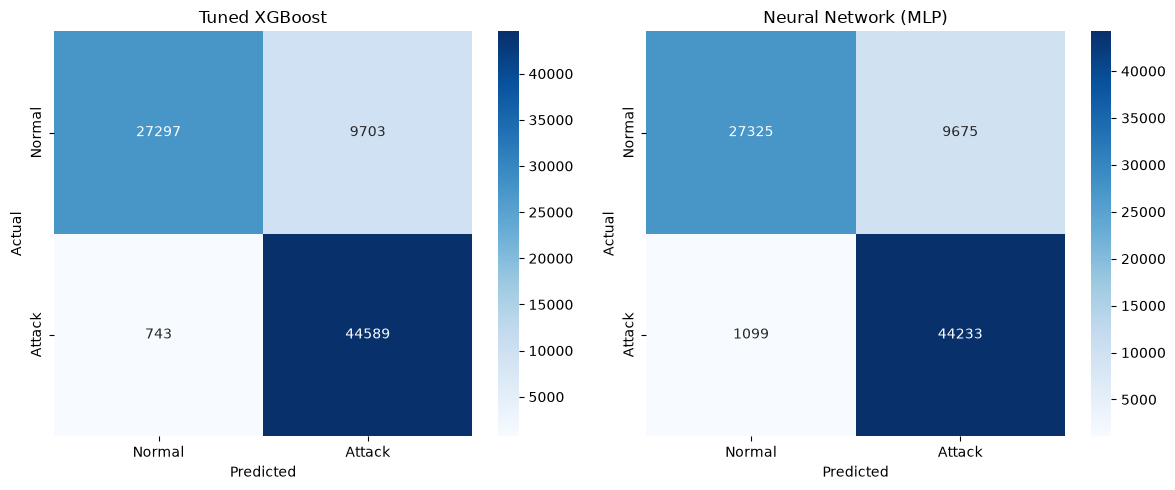

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models_predictions = [
    ("Tuned XGBoost", xgb_pred),
    ("Neural Network (MLP)", nn_pred)
]

for ax, (name, predictions) in zip(
    axes,
    models_predictions
):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Normal", "Attack"],
        yticklabels=["Normal", "Attack"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ml_vs_dl_confusion_matrices.png",
    dpi=300
)

plt.show()

### **17. Training History**

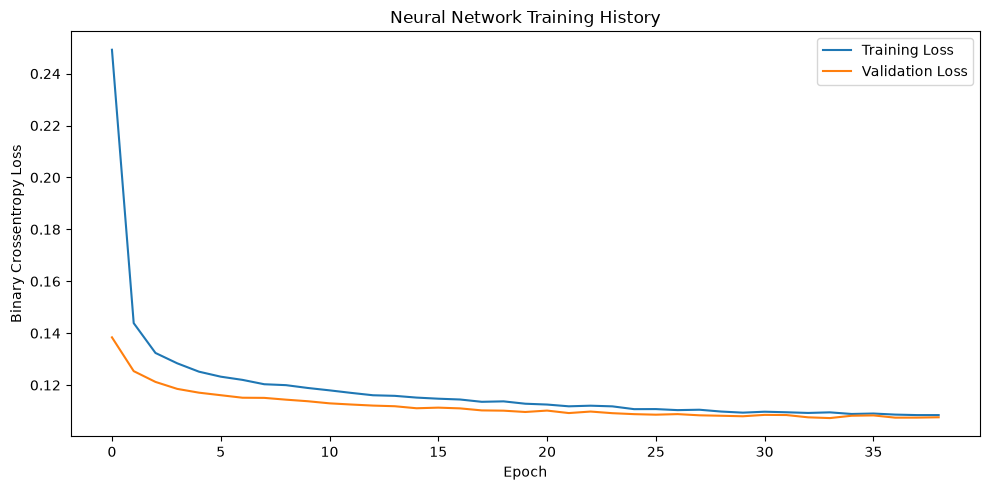

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Neural Network Training History")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "neural_network_training_history.png",
    dpi=300
)

plt.show()

### **18. Save Neural Network and Preprocessor**

In [20]:

final_nn_model.save(
    RESULTS_DIR / "neural_network_model.keras"
)

joblib.dump(
    final_nn_preprocessor,
    RESULTS_DIR / "neural_network_preprocessor.joblib"
)

['c:\\PK\\Projects\\network-intrusion\\capstone\\results\\neural_network_preprocessor.joblib']

### **19. Final Summary**

In [21]:
best_model_name = comparison_df.iloc[0]["Model"]

print("\n" + "=" * 65)
print("ML VS DL EXPERIMENT COMPLETED")
print("=" * 65)

print("Best model based on F1 Score:", best_model_name)

print("\nSaved files:")
print("- ml_vs_dl_comparison.csv")
print("- ml_vs_dl_comparison.png")
print("- ml_vs_dl_confusion_matrices.png")
print("- neural_network_training_history.png")
print("- neural_network_model.keras")
print("- neural_network_preprocessor.joblib")

print("\nResults directory:", RESULTS_DIR)


ML VS DL EXPERIMENT COMPLETED
Best model based on F1 Score: Tuned XGBoost

Saved files:
- ml_vs_dl_comparison.csv
- ml_vs_dl_comparison.png
- ml_vs_dl_confusion_matrices.png
- neural_network_training_history.png
- neural_network_model.keras
- neural_network_preprocessor.joblib

Results directory: c:\PK\Projects\network-intrusion\capstone\results
